# UrbanSense AI — Business Understanding, EDA, dan Evaluasi Model

Notebook ini menyajikan proses analitik prediksi risiko banjir Kota Bandung secara langsung dan berurutan: **business understanding → data understanding → exploratory data analysis (EDA) → pemodelan → evaluasi → interpretasi**.

Notebook ini hanya membaca dataset yang sudah tersedia. Proses akuisisi dan pembentukan dataset tetap tersedia pada script pipeline (`fetch_bandung_data.py`, `01_build_training_data.py`, dan `01b_integrate_real_data.py`).

## 1. Business Understanding

### Latar belakang bisnis
Banjir perkotaan dipengaruhi oleh kombinasi intensitas hujan, kondisi topografi, kepadatan bangunan dan penduduk, jaringan sungai, serta kapasitas drainase. Pemerintah kota dan tim tanggap bencana membutuhkan indikasi risiko yang dapat dibandingkan antar-kecamatan dan antar-skenario agar prioritas mitigasi dapat ditentukan lebih cepat.

### Tujuan bisnis
1. Mengidentifikasi kecamatan dan skenario dengan risiko banjir paling tinggi.
2. Menyediakan skor risiko 0–100 dan tier **low / medium / high** yang mudah dipahami.
3. Menjelaskan faktor yang paling berkontribusi terhadap skor sehingga hasil model dapat ditindaklanjuti.

### Pertanyaan analitik
- Bagaimana distribusi skor risiko pada seluruh kecamatan dan skenario?
- Apakah hujan ekstrem dan kegagalan drainase menaikkan risiko secara konsisten?
- Fitur fisik dan sosial apa yang paling terkait dengan `risk_score`?
- Apakah model memberikan kinerja yang lebih baik daripada baseline sederhana?

### Keputusan yang didukung
Hasil analisis dapat digunakan untuk prioritas inspeksi drainase, penentuan area pemantauan saat hujan ekstrem, dan komunikasi risiko. Skor ini adalah alat bantu keputusan, bukan pengganti validasi lapangan atau peringatan resmi.

## 2. Data Understanding dan Asumsi

Dataset merupakan gabungan fitur geospasial/OSM, topografi, demografi, curah hujan, dan empat skenario simulasi. Target `risk_score` dibentuk menggunakan aturan berbasis hazard, vulnerability, dan capacity pada pipeline saat ini.

**Catatan penting:** dataset berisi 30 kecamatan × 4 skenario. Observasi beberapa skenario berasal dari kecamatan yang sama, sehingga hasil evaluasi perlu dibaca sebagai evaluasi internal terhadap dataset simulasi, bukan bukti performa pada data kejadian banjir baru. Dataset ini juga tidak boleh dianggap sebagai ground truth lapangan tanpa validasi historis.

In [3]:
from pathlib import Path
import json
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore", category=FutureWarning)
plt.style.use("seaborn-v0_8-whitegrid")
pd.set_option("display.max_columns", 50)

try:
    import seaborn as sns
except ImportError:
    sns = None
    print("Seaborn tidak tersedia; visualisasi akan memakai matplotlib.")

def find_pipeline_dir():
    """Temukan backend/ml_pipeline dari root repo atau lokasi notebook."""
    candidates = [
        Path.cwd() / "backend" / "ml_pipeline",
        Path.cwd(),
        Path(__file__).resolve().parent if "__file__" in globals() else Path.cwd(),
    ]
    for candidate in candidates:
        if (candidate / "data").is_dir():
            return candidate
    raise FileNotFoundError(
        "Folder backend/ml_pipeline/data tidak ditemukan. "
        "Jalankan notebook dari root repository atau folder ml_pipeline."
    )

PIPELINE_DIR = find_pipeline_dir()
DATA_DIR = PIPELINE_DIR / "data"
DATA_PATH = DATA_DIR / "training_dataset_v2.csv"
if not DATA_PATH.exists():
    DATA_PATH = DATA_DIR / "training_dataset.csv"

df = pd.read_csv(DATA_PATH)
print(f"Dataset: {DATA_PATH}")
print(f"Ukuran: {df.shape[0]} baris × {df.shape[1]} kolom")
display(df.head())

Dataset: d:\Farid2\Project\urbansense-ai\backend\ml_pipeline\data\training_dataset_v2.csv
Ukuran: 120 baris × 24 kolom


,districtId,district,scenario,rainfall_mm,elevation_mean,slope_mean,population_density,drainage_density_km,river_density_km,road_density,building_density,green_ratio,water_ratio,facility_density,impervious_ratio,basin_depression_index,effective_drainage_capacity,hazard_index,vulnerability_index,capacity_index,risk_score,risk_level,confidence,recommendation
0,andir,Andir,current,69.7,727.4,0.83,17800.0,0.703,1.111,2.896,198.50,0.1622,0.0301,3.156,0.231,0.622,0.703,51.46,41.83,33.75,42,medium,90,Peningkatan kapasitas drainase primer & polder...
1,andir,Andir,heavy_rain_24h,151.5,727.4,0.83,17800.0,0.703,1.111,2.896,198.50,0.1622,0.0301,3.156,0.231,0.622,0.647,63.97,41.83,23.31,52,medium,88,Peningkatan kapasitas drainase primer & polder...
2,andir,Andir,heavy_rain_72h,260.6,727.4,0.83,17800.0,0.703,1.111,2.896,198.50,0.1622,0.0301,3.156,0.231,0.622,0.562,79.97,41.83,14.80,64,medium,84,Peningkatan kapasitas drainase primer & polder...
3,andir,Andir,drainage_failure,117.4,727.4,0.83,17800.0,0.703,1.111,2.896,198.50,0.1622,0.0301,3.156,0.231,0.622,0.316,58.28,41.83,17.98,50,medium,91,Peningkatan kapasitas drainase primer & polder...
4,antapani,Antapani,current,70.5,682.8,0.37,18200.0,0.752,0.478,8.210,106.76,0.1188,0.0143,3.145,0.291,0.892,0.752,52.83,44.53,30.40,45,medium,83,Peningkatan kapasitas drainase primer & polder...


## 3. Data Quality Check

Pemeriksaan awal mencakup tipe data, duplikasi, nilai kosong, dan rentang target. Temuan di tahap ini menjadi dasar sebelum membuat visualisasi atau melatih model.

In [4]:
print("Tipe data:")
display(df.dtypes.to_frame("dtype"))

quality = pd.DataFrame({
    "missing": df.isna().sum(),
    "missing_pct": (df.isna().mean() * 100).round(2),
    "n_unique": df.nunique(),
})
print("Ringkasan kualitas data:")
display(quality[quality["missing"] > 0].sort_values("missing", ascending=False))
print(f"Duplikasi baris: {df.duplicated().sum()}")
print(f"Rentang risk_score: {df['risk_score'].min():.2f} – {df['risk_score'].max():.2f}")
display(df.describe(include="all").T)

Tipe data:


,dtype
districtId,str
district,str
scenario,str
rainfall_mm,float64
elevation_mean,float64
slope_mean,float64
population_density,float64
drainage_density_km,float64
river_density_km,float64
road_density,float64


Ringkasan kualitas data:


,missing,missing_pct,n_unique


Duplikasi baris: 0
Rentang risk_score: 15.00 – 77.00


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
districtId,120,30,andir,4,NaN,NaN,NaN,NaN,NaN,NaN,NaN
district,120,30,Andir,4,NaN,NaN,NaN,NaN,NaN,NaN,NaN
scenario,120,4,current,30,NaN,NaN,NaN,NaN,NaN,NaN,NaN
rainfall_mm,120.0,NaN,NaN,NaN,139.104167,70.734001,37.6,70.5,118.3,152.4,289.3
elevation_mean,120.0,NaN,NaN,NaN,717.126667,55.917502,666.0,682.8,697.0,735.4,898.0
slope_mean,120.0,NaN,NaN,NaN,1.145667,1.150961,0.07,0.36,0.625,1.62,4.35
population_density,120.0,NaN,NaN,NaN,14716.666667,4210.03869,5800.0,12400.0,14350.0,17800.0,23500.0
drainage_density_km,120.0,NaN,NaN,NaN,1.452167,0.625255,0.52,0.869,1.451,1.724,2.829
river_density_km,120.0,NaN,NaN,NaN,1.1386,0.594375,0.241,0.644,1.121,1.446,2.655
road_density,120.0,NaN,NaN,NaN,8.743833,4.476009,2.223,5.812,8.082,9.832,20.525


## 4. Exploratory Data Analysis (EDA)

### 4.1 Distribusi target dan komposisi skenario
Distribusi `risk_score` menunjukkan variasi tingkat risiko yang perlu dipelajari model. Perbandingan skenario membantu memeriksa apakah simulasi hujan ekstrem dan kegagalan drainase menghasilkan perubahan yang masuk akal.

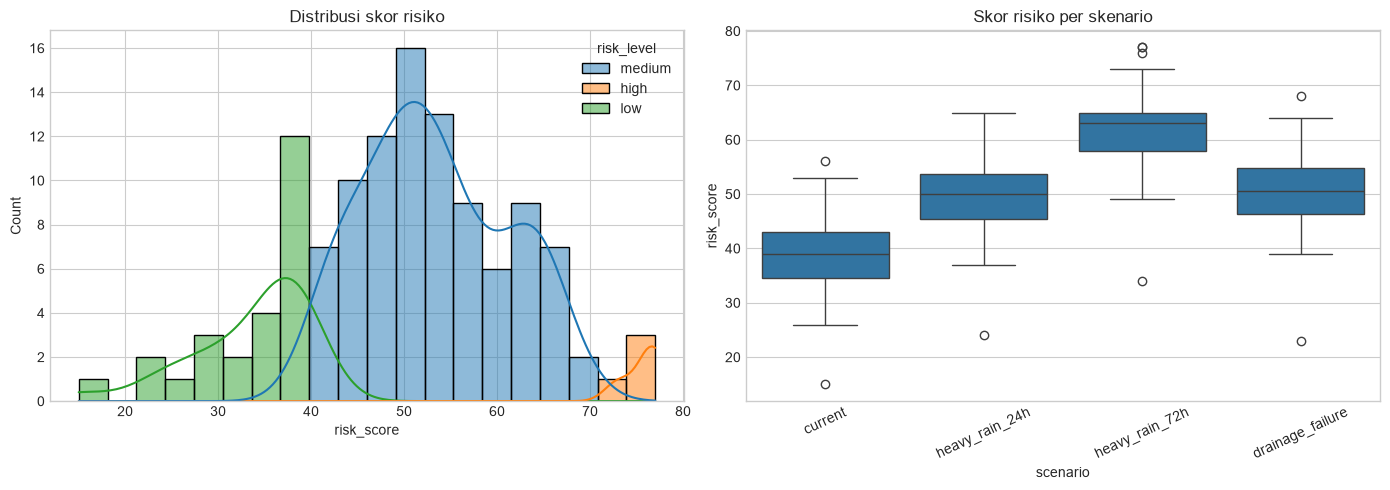

,observations,mean_risk,median_risk,min_risk,max_risk
scenario,,,,,
heavy_rain_72h,30,61.57,63.0,34,77
drainage_failure,30,50.07,50.5,23,68
heavy_rain_24h,30,49.40,50.0,24,65
current,30,38.77,39.0,15,56


In [5]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
if sns is not None:
    sns.histplot(data=df, x="risk_score", hue="risk_level", bins=20, kde=True, ax=axes[0])
    sns.boxplot(data=df, x="scenario", y="risk_score", ax=axes[1])
else:
    axes[0].hist(df["risk_score"], bins=20, edgecolor="white")
    df.boxplot(column="risk_score", by="scenario", ax=axes[1], rot=25)
axes[0].set_title("Distribusi skor risiko")
axes[1].set_title("Skor risiko per skenario")
axes[1].tick_params(axis="x", rotation=25)
plt.tight_layout()
plt.show()

scenario_summary = df.groupby("scenario").agg(
    observations=("risk_score", "size"),
    mean_risk=("risk_score", "mean"),
    median_risk=("risk_score", "median"),
    min_risk=("risk_score", "min"),
    max_risk=("risk_score", "max"),
).sort_values("mean_risk", ascending=False).round(2)
display(scenario_summary)

### 4.2 Kecamatan dengan risiko tertinggi
Agregasi per kecamatan membantu menjawab kebutuhan prioritas wilayah. Nilai di bawah ini dirangkum dari seluruh skenario, sehingga perlu dibaca bersama konteks skenarionya.

,mean_risk,max_risk,mean_rainfall,mean_elevation,mean_drainage_capacity
district,,,,,
Bojongloa Kidul,65.50,77,150.67,683.2,1.97
Babakan Ciparay,65.25,76,150.48,693.2,0.61
Arcamanik,64.50,77,139.12,673.6,0.81
Buah Batu,60.25,73,150.80,675.8,0.47
Astana Anyar,56.00,69,150.38,698.8,0.63
Lengkong,55.00,67,150.43,694.6,1.12
Rancasari,54.25,65,78.72,670.2,1.66
Antapani,54.25,65,150.67,682.8,0.60
Bandung Kulon,54.00,66,129.78,695.2,1.83


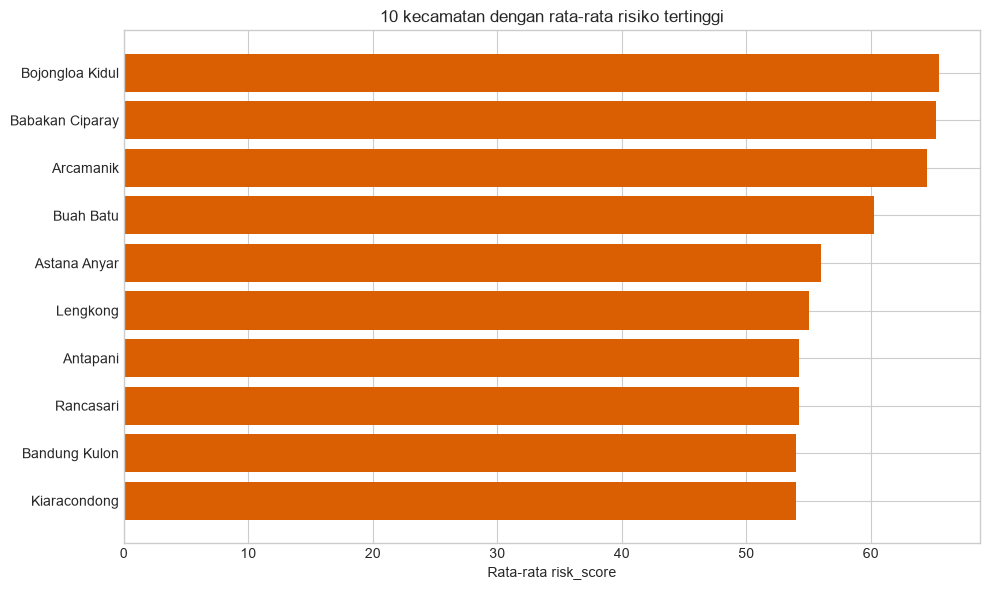

In [6]:
district_summary = df.groupby("district").agg(
    mean_risk=("risk_score", "mean"),
    max_risk=("risk_score", "max"),
    mean_rainfall=("rainfall_mm", "mean"),
    mean_elevation=("elevation_mean", "mean"),
    mean_drainage_capacity=("effective_drainage_capacity", "mean"),
).sort_values("mean_risk", ascending=False)
display(district_summary.head(10).round(2))

top = district_summary.head(10).sort_values("mean_risk")
plt.figure(figsize=(10, 6))
plt.barh(top.index, top["mean_risk"], color="#d95f02")
plt.xlabel("Rata-rata risk_score")
plt.title("10 kecamatan dengan rata-rata risiko tertinggi")
plt.tight_layout()
plt.show()

### 4.3 Hubungan fitur numerik dengan risiko
Korelasi adalah indikasi awal, bukan bukti sebab-akibat. Untuk fitur yang memiliki hubungan non-linear atau saling berkorelasi, interpretasi model dan validasi domain tetap diperlukan.

,correlation_with_risk_score
elevation_mean,-0.529
slope_mean,-0.449
capacity_index,-0.326
effective_drainage_capacity,-0.140
confidence,-0.005
drainage_density_km,-0.004
water_ratio,0.024
green_ratio,0.164
facility_density,0.292
river_density_km,0.328


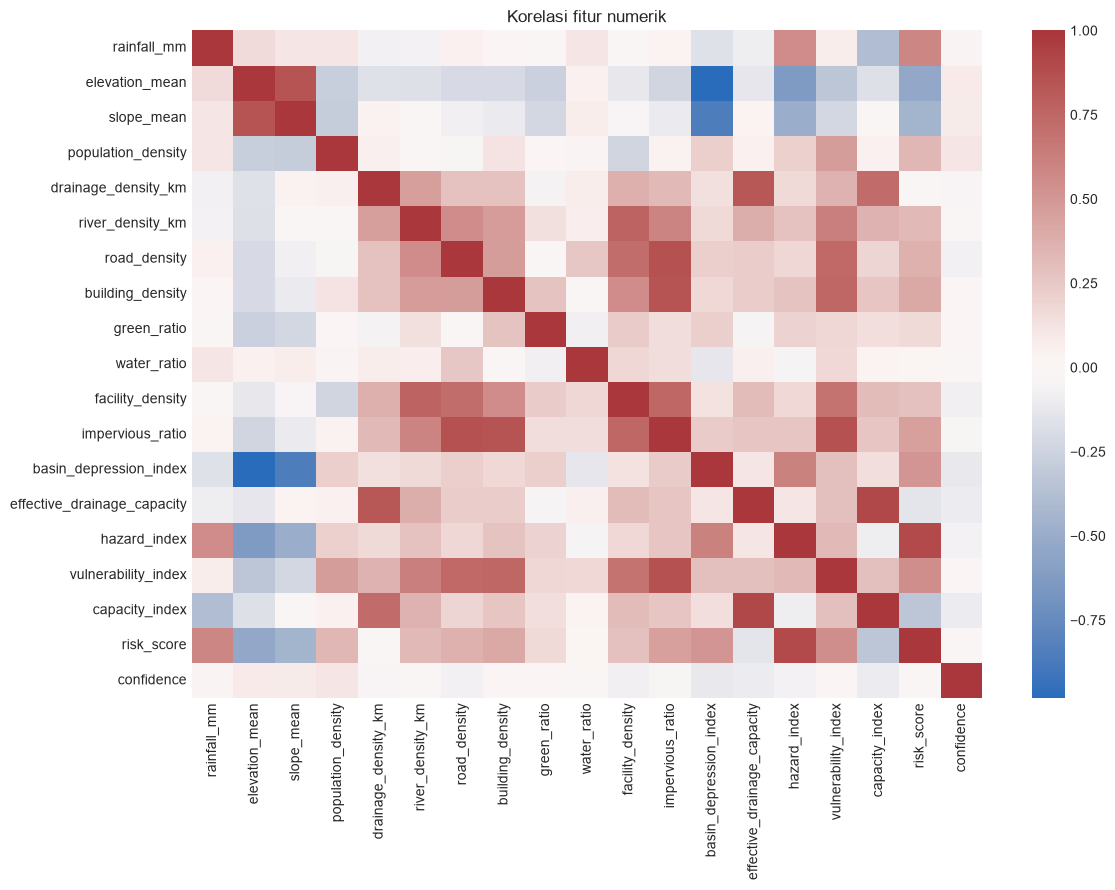

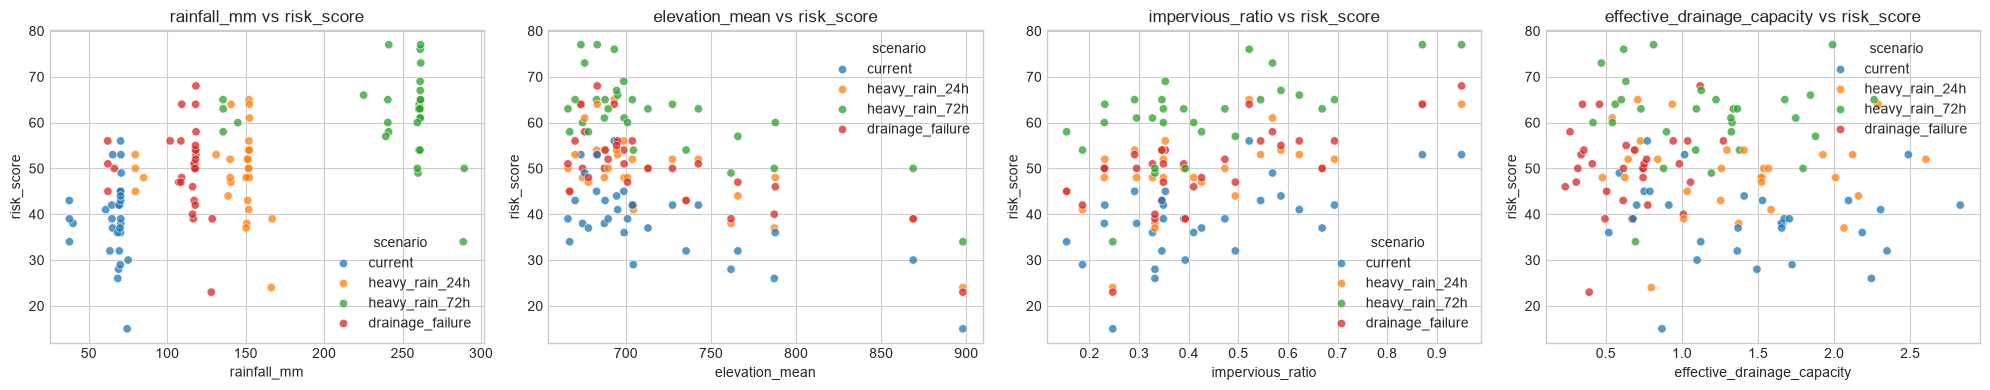

In [7]:
numeric_cols = df.select_dtypes(include="number").columns
corr = df[numeric_cols].corr(numeric_only=True)
risk_corr = corr["risk_score"].drop("risk_score").sort_values()
display(risk_corr.to_frame("correlation_with_risk_score").round(3))

plt.figure(figsize=(12, 9))
if sns is not None:
    sns.heatmap(corr, cmap="vlag", center=0, annot=False)
else:
    plt.imshow(corr, cmap="coolwarm", aspect="auto", vmin=-1, vmax=1)
    plt.colorbar(label="Correlation")
    plt.xticks(range(len(corr.columns)), corr.columns, rotation=90)
    plt.yticks(range(len(corr.index)), corr.index)
plt.title("Korelasi fitur numerik")
plt.tight_layout()
plt.show()

selected = [c for c in ["rainfall_mm", "elevation_mean", "impervious_ratio", "effective_drainage_capacity"] if c in df]
fig, axes = plt.subplots(1, len(selected), figsize=(5 * len(selected), 4))
axes = np.atleast_1d(axes)
for ax, col in zip(axes, selected):
    if sns is not None:
        sns.scatterplot(data=df, x=col, y="risk_score", hue="scenario", ax=ax, alpha=0.75)
    else:
        for scenario, group in df.groupby("scenario"):
            ax.scatter(group[col], group["risk_score"], label=scenario, alpha=0.75)
        ax.legend()
    ax.set_title(f"{col} vs risk_score")
plt.tight_layout()
plt.show()

## 5. Pemodelan dan Evaluasi Internal

Bagian ini mereplikasi evaluasi inti pipeline dengan 5-fold cross-validation. Model yang digunakan adalah `XGBRegressor`, sedangkan pembandingnya adalah `DummyRegressor(strategy='mean')`. Target dikonversi menjadi tier: **low < 40**, **medium 40–69**, dan **high ≥ 70**.

Jika dependensi XGBoost belum tersedia, sel ini akan memberikan pesan yang jelas dan notebook tetap dapat digunakan untuk business understanding serta EDA.

In [8]:
from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import KFold

FEATURE_COLUMNS = [
    "rainfall_mm", "elevation_mean", "slope_mean", "population_density",
    "drainage_density_km", "river_density_km", "road_density",
    "building_density", "green_ratio", "water_ratio", "facility_density",
    "impervious_ratio", "basin_depression_index", "effective_drainage_capacity",
]

def to_risk_tier(score):
    if score >= 70:
        return "high"
    if score >= 40:
        return "medium"
    return "low"

available_features = [col for col in FEATURE_COLUMNS if col in df.columns]
X = df[available_features]
y = df["risk_score"].to_numpy()
kf = KFold(n_splits=5, shuffle=True, random_state=42)
rows = []

try:
    import xgboost as xgb
    for fold, (train_idx, val_idx) in enumerate(kf.split(X), start=1):
        model = xgb.XGBRegressor(
            n_estimators=120, max_depth=3, learning_rate=0.08,
            subsample=0.85, colsample_bytree=0.85, random_state=42,
        )
        model.fit(X.iloc[train_idx], y[train_idx])
        pred = model.predict(X.iloc[val_idx])
        tier_acc = np.mean([
            to_risk_tier(actual) == to_risk_tier(predicted)
            for actual, predicted in zip(y[val_idx], pred)
        ])
        rows.append({
            "fold": fold,
            "model": "XGBoost",
            "MAE": mean_absolute_error(y[val_idx], pred),
            "RMSE": np.sqrt(mean_squared_error(y[val_idx], pred)),
            "R2": r2_score(y[val_idx], pred),
            "tier_accuracy": tier_acc,
        })
        
    for fold, (train_idx, val_idx) in enumerate(kf.split(X), start=1):
        baseline = DummyRegressor(strategy="mean")
        baseline.fit(X.iloc[train_idx], y[train_idx])
        pred = baseline.predict(X.iloc[val_idx])
        rows.append({
            "fold": fold,
            "model": "Dummy mean",
            "MAE": mean_absolute_error(y[val_idx], pred),
            "RMSE": np.sqrt(mean_squared_error(y[val_idx], pred)),
            "R2": r2_score(y[val_idx], pred),
            "tier_accuracy": np.mean([
                to_risk_tier(actual) == to_risk_tier(predicted)
                for actual, predicted in zip(y[val_idx], pred)
            ]),
        })
    cv_results = pd.DataFrame(rows)
    display(cv_results.round(3))
    display(cv_results.groupby("model").mean(numeric_only=True).round(3))
except ImportError as exc:
    print(f"XGBoost belum tersedia ({exc}). Lewati evaluasi model; EDA tetap berhasil.")

,fold,model,MAE,RMSE,R2,tier_accuracy
0,1,XGBoost,4.155,4.948,0.890,0.875
1,2,XGBoost,3.101,3.607,0.875,0.958
2,3,XGBoost,2.332,3.382,0.913,0.917
3,4,XGBoost,3.160,3.588,0.884,0.833
4,5,XGBoost,2.775,3.289,0.906,0.917
5,1,Dummy mean,12.565,15.138,-0.025,0.625
6,2,Dummy mean,8.602,10.550,-0.065,0.875
7,3,Dummy mean,8.745,11.488,-0.002,0.750
8,4,Dummy mean,8.255,10.536,-0.000,0.750
9,5,Dummy mean,8.425,10.745,-0.001,0.792


,fold,MAE,RMSE,R2,tier_accuracy
model,,,,,
Dummy mean,3.0,9.318,11.691,-0.019,0.758
XGBoost,3.0,3.105,3.763,0.894,0.900


## 6. Ringkasan Insight dan Tindak Lanjut

Gunakan output tabel dan grafik di atas untuk mengisi kesimpulan berbasis angka saat notebook dijalankan. Minimal, laporkan:

- skenario dengan rata-rata `risk_score` tertinggi;
- tiga kecamatan dengan rata-rata atau risiko maksimum tertinggi;
- fitur dengan korelasi absolut terbesar terhadap target;
- perbandingan MAE dan akurasi tier model terhadap baseline;
- keterbatasan dataset simulasi dan rencana validasi dengan kejadian banjir historis.

Untuk interpretasi model berbasis SHAP yang sudah terintegrasi dengan artefak aplikasi, lanjutkan dengan `03_evaluate_shap.py`. Notebook ini sengaja memisahkan EDA dari pembuatan artefak produksi agar eksplorasi tidak mengubah file model maupun dataset.